In [1]:
%matplotlib inline
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D 
from matplotlib import gridspec

import seaborn as sns


plt.rcParams['figure.dpi'] = 300
plt.rcParams['font.size'] = 14
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = [font for font in 'Liberation Sans, DejaVu Sans, Arial, Helvetica, Lucida Grande, Verdana, Geneva, Lucid, Avant Garde, sans-serif'.split(', ')] 
plt.rcParams['mathtext.fontset'] = 'stixsans'

plt.rcParams['axes.linewidth'] = 1
plt.rcParams['grid.linewidth'] = 1
plt.rcParams['lines.linewidth'] = 2
plt.rcParams['lines.markersize'] = 6


In [2]:
cat_colors_list = [ '#263238','#2E5BFF', "#D4AF37", '#D81B60', '#558B2F', '#7B1FA2', '#E65100']  # ,   '#94A3B8' 
unique_categories = ['common',  'SADE unique', 'CR unique', 'TSS unique',  'SADE+CR, not TSS', 'SADE+TSS, not CR', 'CR+TSS, not SADE', ]
cat_colors_map = dict(zip(unique_categories, cat_colors_list))    


In [7]:
## Downloaded CR-arc count matrix results
data_dir = '/mnt/hdd_bob/syy/adipose/atac/protocol_benchmark/downloaded_counts/VIB_10xmultiome_2'

## Entropy filtered atac
entropy_dir = '/mnt/hdd_bob/syy/adipose/atac/res/VIB_10xmultiome_2_WS3000F'
union_cells_dir = os.path.join(entropy_dir, '_cell_calling_comparison')

# Load peak annotations [including peak AUC score from Genrich peaks]
# Raw peaks are inferred with all reads 
raw_peaks_annot = pd.read_csv(os.path.join(union_cells_dir, 'Rawpeaks/annotation', 'annotated_peaks.bed'),      sep='\t')
raw_peaks_annot['peak_size'] = raw_peaks_annot['End'] - raw_peaks_annot['Start']

# Common peaks are inferred with the common droplets from 3 nuclei-filtering sets (SADE, CR, TSSe)
common_peaks_annot_file = os.path.join(union_cells_dir, 'Commoncells_peaks/annotation', 'annotated_peaks.bed')
common_peaks_annot = pd.read_csv(common_peaks_annot_file, sep='\t')
common_peaks_annot['peak_size'] = common_peaks_annot['End'] - common_peaks_annot['Start']

sade_peaks_annot_file = os.path.join(union_cells_dir, 'Entropy_cells_peaks/annotation/', 'annotated_peaks.bed')
cr_peaks_annot_file = os.path.join(union_cells_dir, 'FRIP_cells_peaks/annotation/', 'annotated_peaks.bed')
tsse_peaks_annot_file = os.path.join(union_cells_dir, 'TSS_cells_peaks/annotation/', 'annotated_peaks.bed')


SADE_vs_raw_annot_sudir = os.path.join(union_cells_dir, 'Entropypeaks_vs_Rawpeaks/annotation')
CR_vs_raw_annot_sudir = os.path.join(union_cells_dir, 'FRIPpeaks_vs_Rawpeaks/annotation')
TSSe_vs_raw_annot_sudir = os.path.join(union_cells_dir, 'TSSpeaks_vs_Rawpeaks/annotation')
common_vs_raw_annot_sudir = os.path.join(union_cells_dir, 'Commonpeaks_vs_Rawpeaks/annotation')

SADE_vs_raw = {}
CR_vs_raw = {}
TSSe_vs_raw = {}
common_vs_raw = {}

for tf, p, d in zip([sade_peaks_annot_file, cr_peaks_annot_file, tsse_peaks_annot_file, common_peaks_annot_file],
    [SADE_vs_raw_annot_sudir, CR_vs_raw_annot_sudir, TSSe_vs_raw_annot_sudir, common_vs_raw_annot_sudir],
                [SADE_vs_raw, CR_vs_raw, TSSe_vs_raw, common_vs_raw]):
    d['whole_peak_set'] = pd.read_csv(tf, sep='\t')
    d['whole_peak_set']['peak_size'] = d['whole_peak_set']['End'] - d['whole_peak_set']['Start']
    
    d['dropped_peaks'] = pd.read_csv(os.path.join(p, 'annotated_lost_peaks.bed'), sep='\t')
    d['newly_discovered_peaks'] = pd.read_csv(os.path.join(p, 'annotated_newly_discovered_peaks.bed'), sep='\t')
    d['dropped_peaks']['peak_size'] = d['dropped_peaks']['End'] - d['dropped_peaks']['Start']
    d['newly_discovered_peaks']['peak_size'] = d['newly_discovered_peaks']['End'] - d['newly_discovered_peaks']['Start']
    

# ---

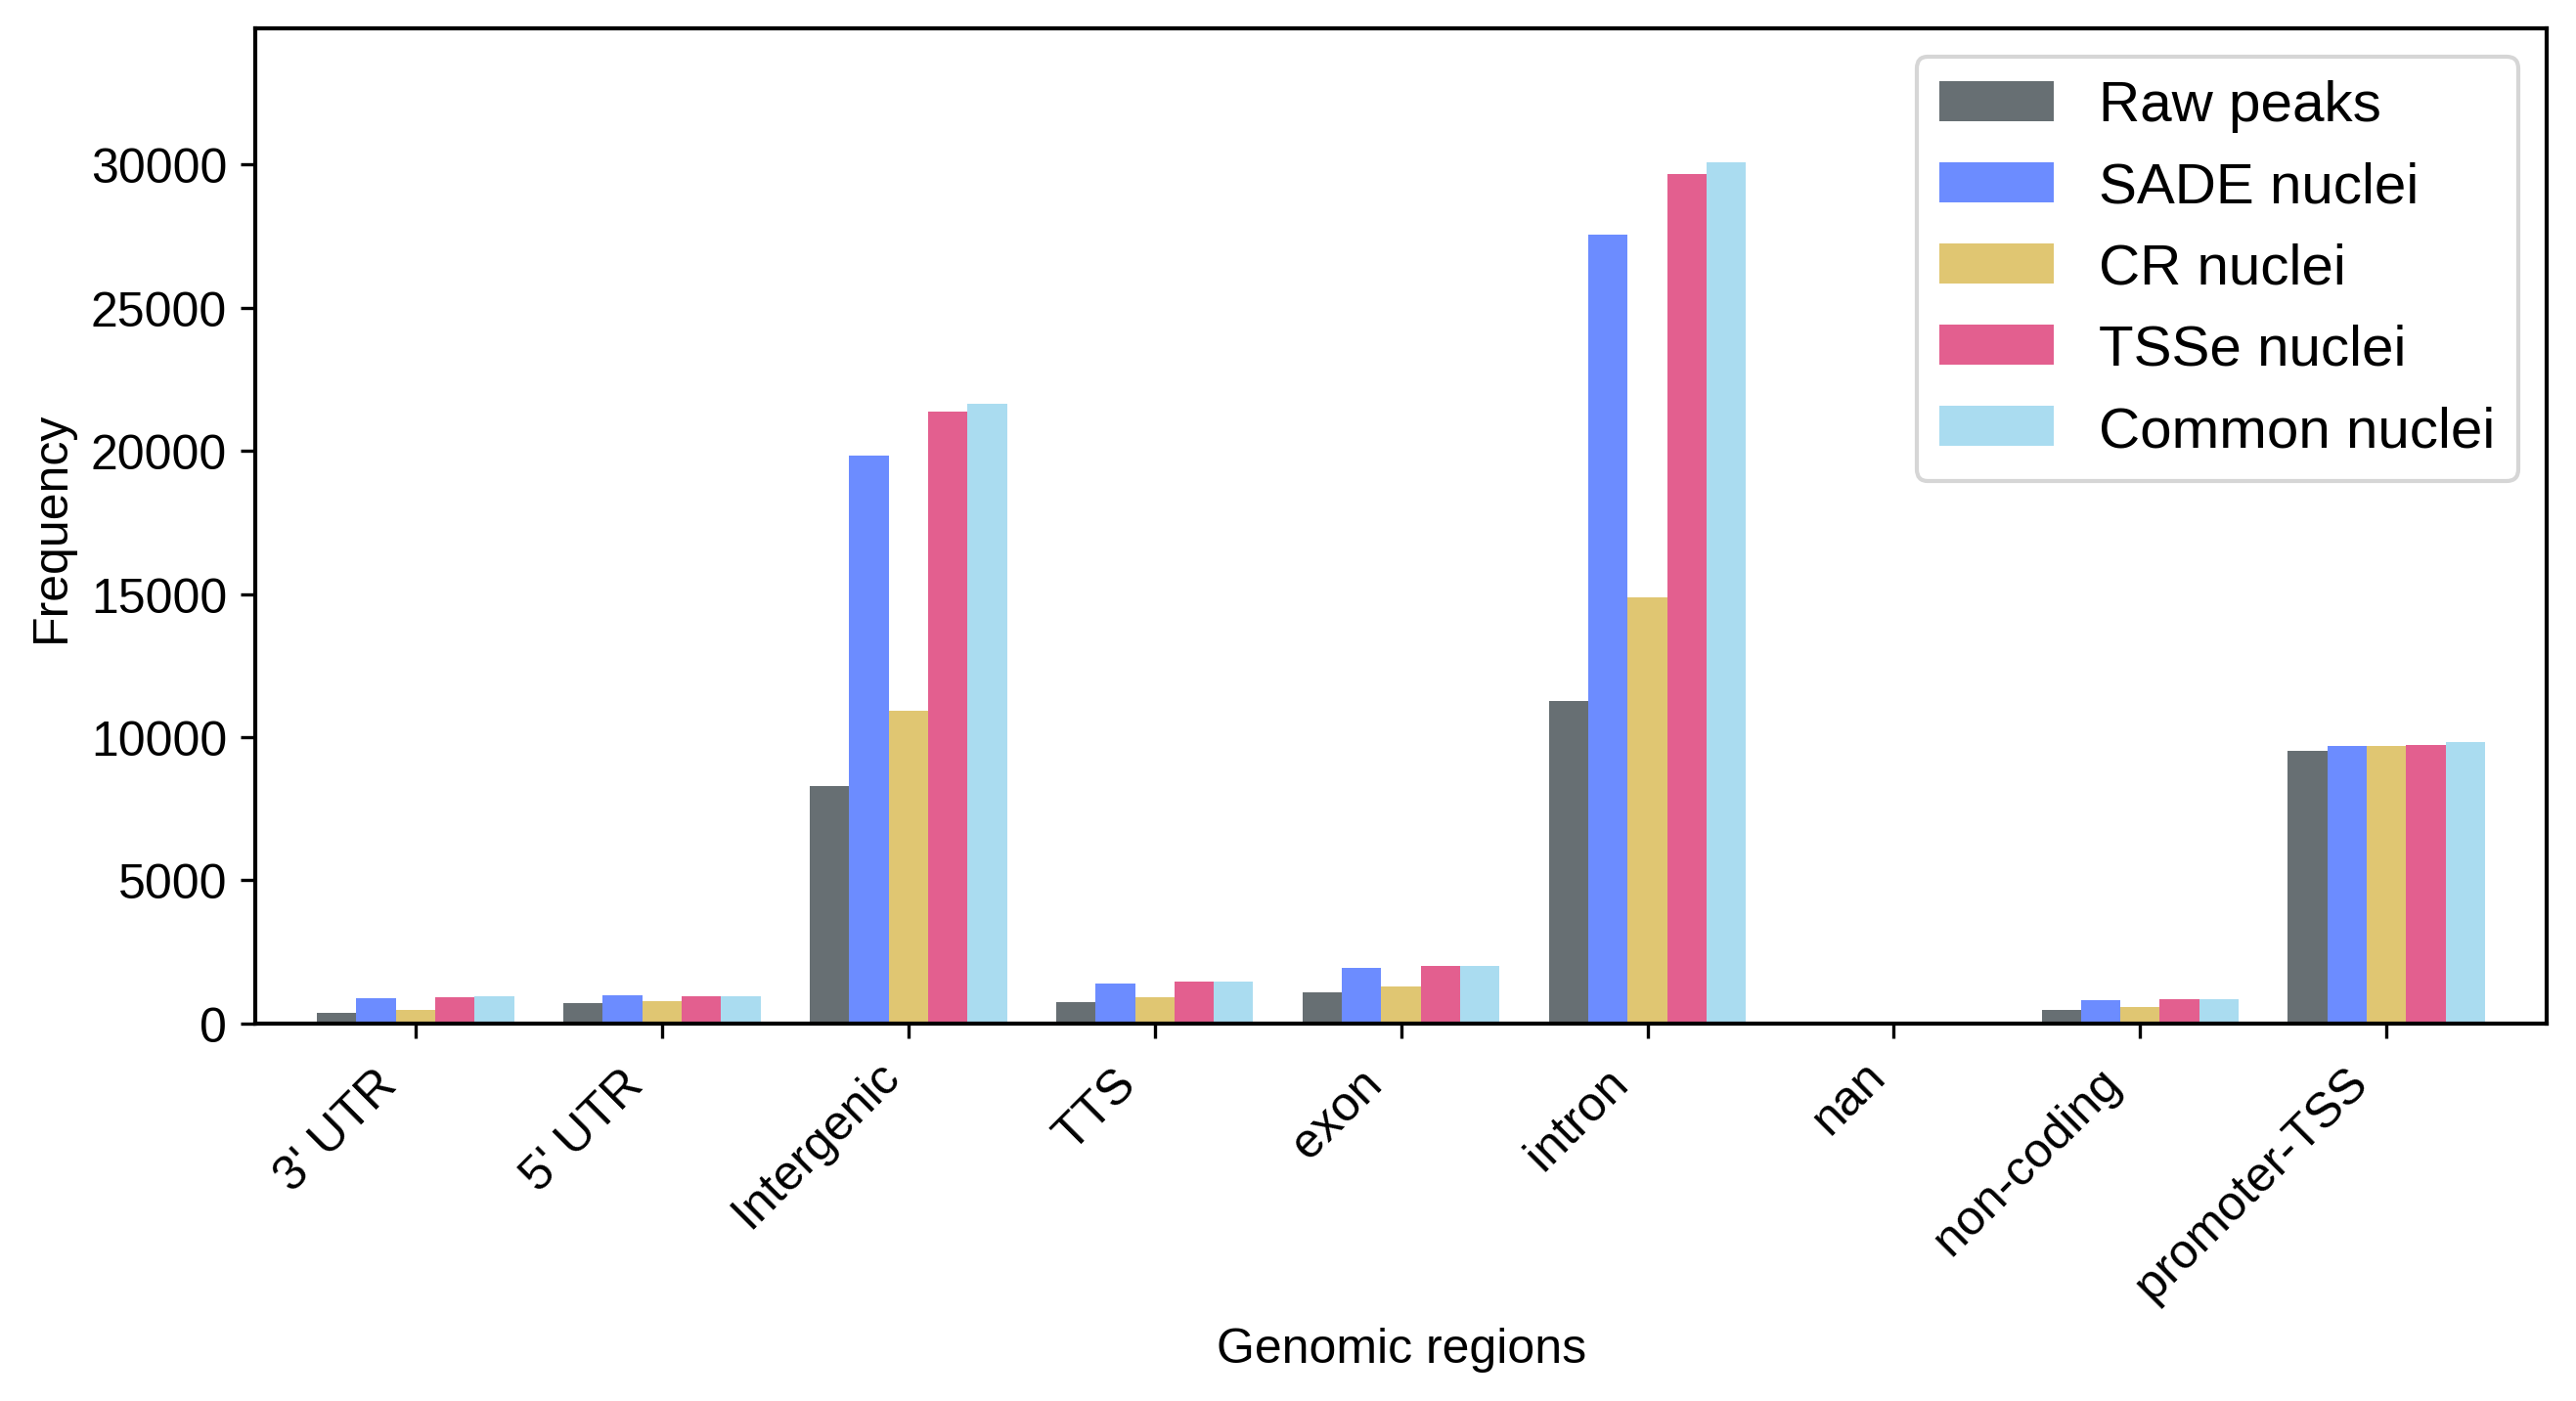

In [11]:
def simplify_annotation(annot_df, inplace=False):
    """
    Simplify the Annotation column.
    """
    if not inplace:
        annot_df = annot_df.copy()
        simple_annotation = annot_df['Annotation'].apply(lambda x: str(x).split('(')[0])  
        return simple_annotation
    else:
        # in place change of the  DataFrame
        annot_df['simple_annotation'] = annot_df['Annotation'].apply(lambda x: str(x).split('(')[0])  
        
simplify_annotation(raw_peaks_annot, inplace=True)
simplify_annotation(SADE_vs_raw['whole_peak_set'], inplace=True)
simplify_annotation(CR_vs_raw['whole_peak_set'], inplace=True)
simplify_annotation(TSSe_vs_raw['whole_peak_set'], inplace=True)
simplify_annotation(common_vs_raw['whole_peak_set'], inplace=True)

        
raw_peak_freq = raw_peaks_annot['simple_annotation'].value_counts()
sade_peak_freq = SADE_vs_raw['whole_peak_set']['simple_annotation'].value_counts()
cr_peak_freq = CR_vs_raw['whole_peak_set']['simple_annotation'].value_counts()
tsse_peak_freq = TSSe_vs_raw['whole_peak_set']['simple_annotation'].value_counts()
common_peak_freq = common_vs_raw['whole_peak_set']['simple_annotation'].value_counts()

freq_df = pd.DataFrame({
    'Raw peaks': raw_peak_freq,
    'SADE nuclei': sade_peak_freq,
    'CR nuclei': cr_peak_freq,
    'TSSe nuclei': tsse_peak_freq,
    'Common nuclei': common_peak_freq
}).fillna(0)

fig, ax = plt.subplots(figsize=(9, 5))
freq_df.plot(kind='bar', width=0.8, alpha=0.7, ax=ax, color=[ '#263238','#2E5BFF', "#D4AF37", '#D81B60', 'skyblue'], fontsize=12)

ax.set_ylim( 0, ax.get_ylim()[1]*1.1)
ax.set_xlabel('Genomic regions', fontsize=12)
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
ax.set_ylabel('Frequency', fontsize=12)
ax.legend()
fig.tight_layout()

[Text(0, 0, 'intron '),
 Text(1, 0, 'promoter-TSS '),
 Text(2, 0, 'Intergenic'),
 Text(3, 0, 'exon '),
 Text(4, 0, "5' UTR "),
 Text(5, 0, 'TTS '),
 Text(6, 0, 'non-coding '),
 Text(7, 0, "3' UTR "),
 Text(8, 0, 'nan')]

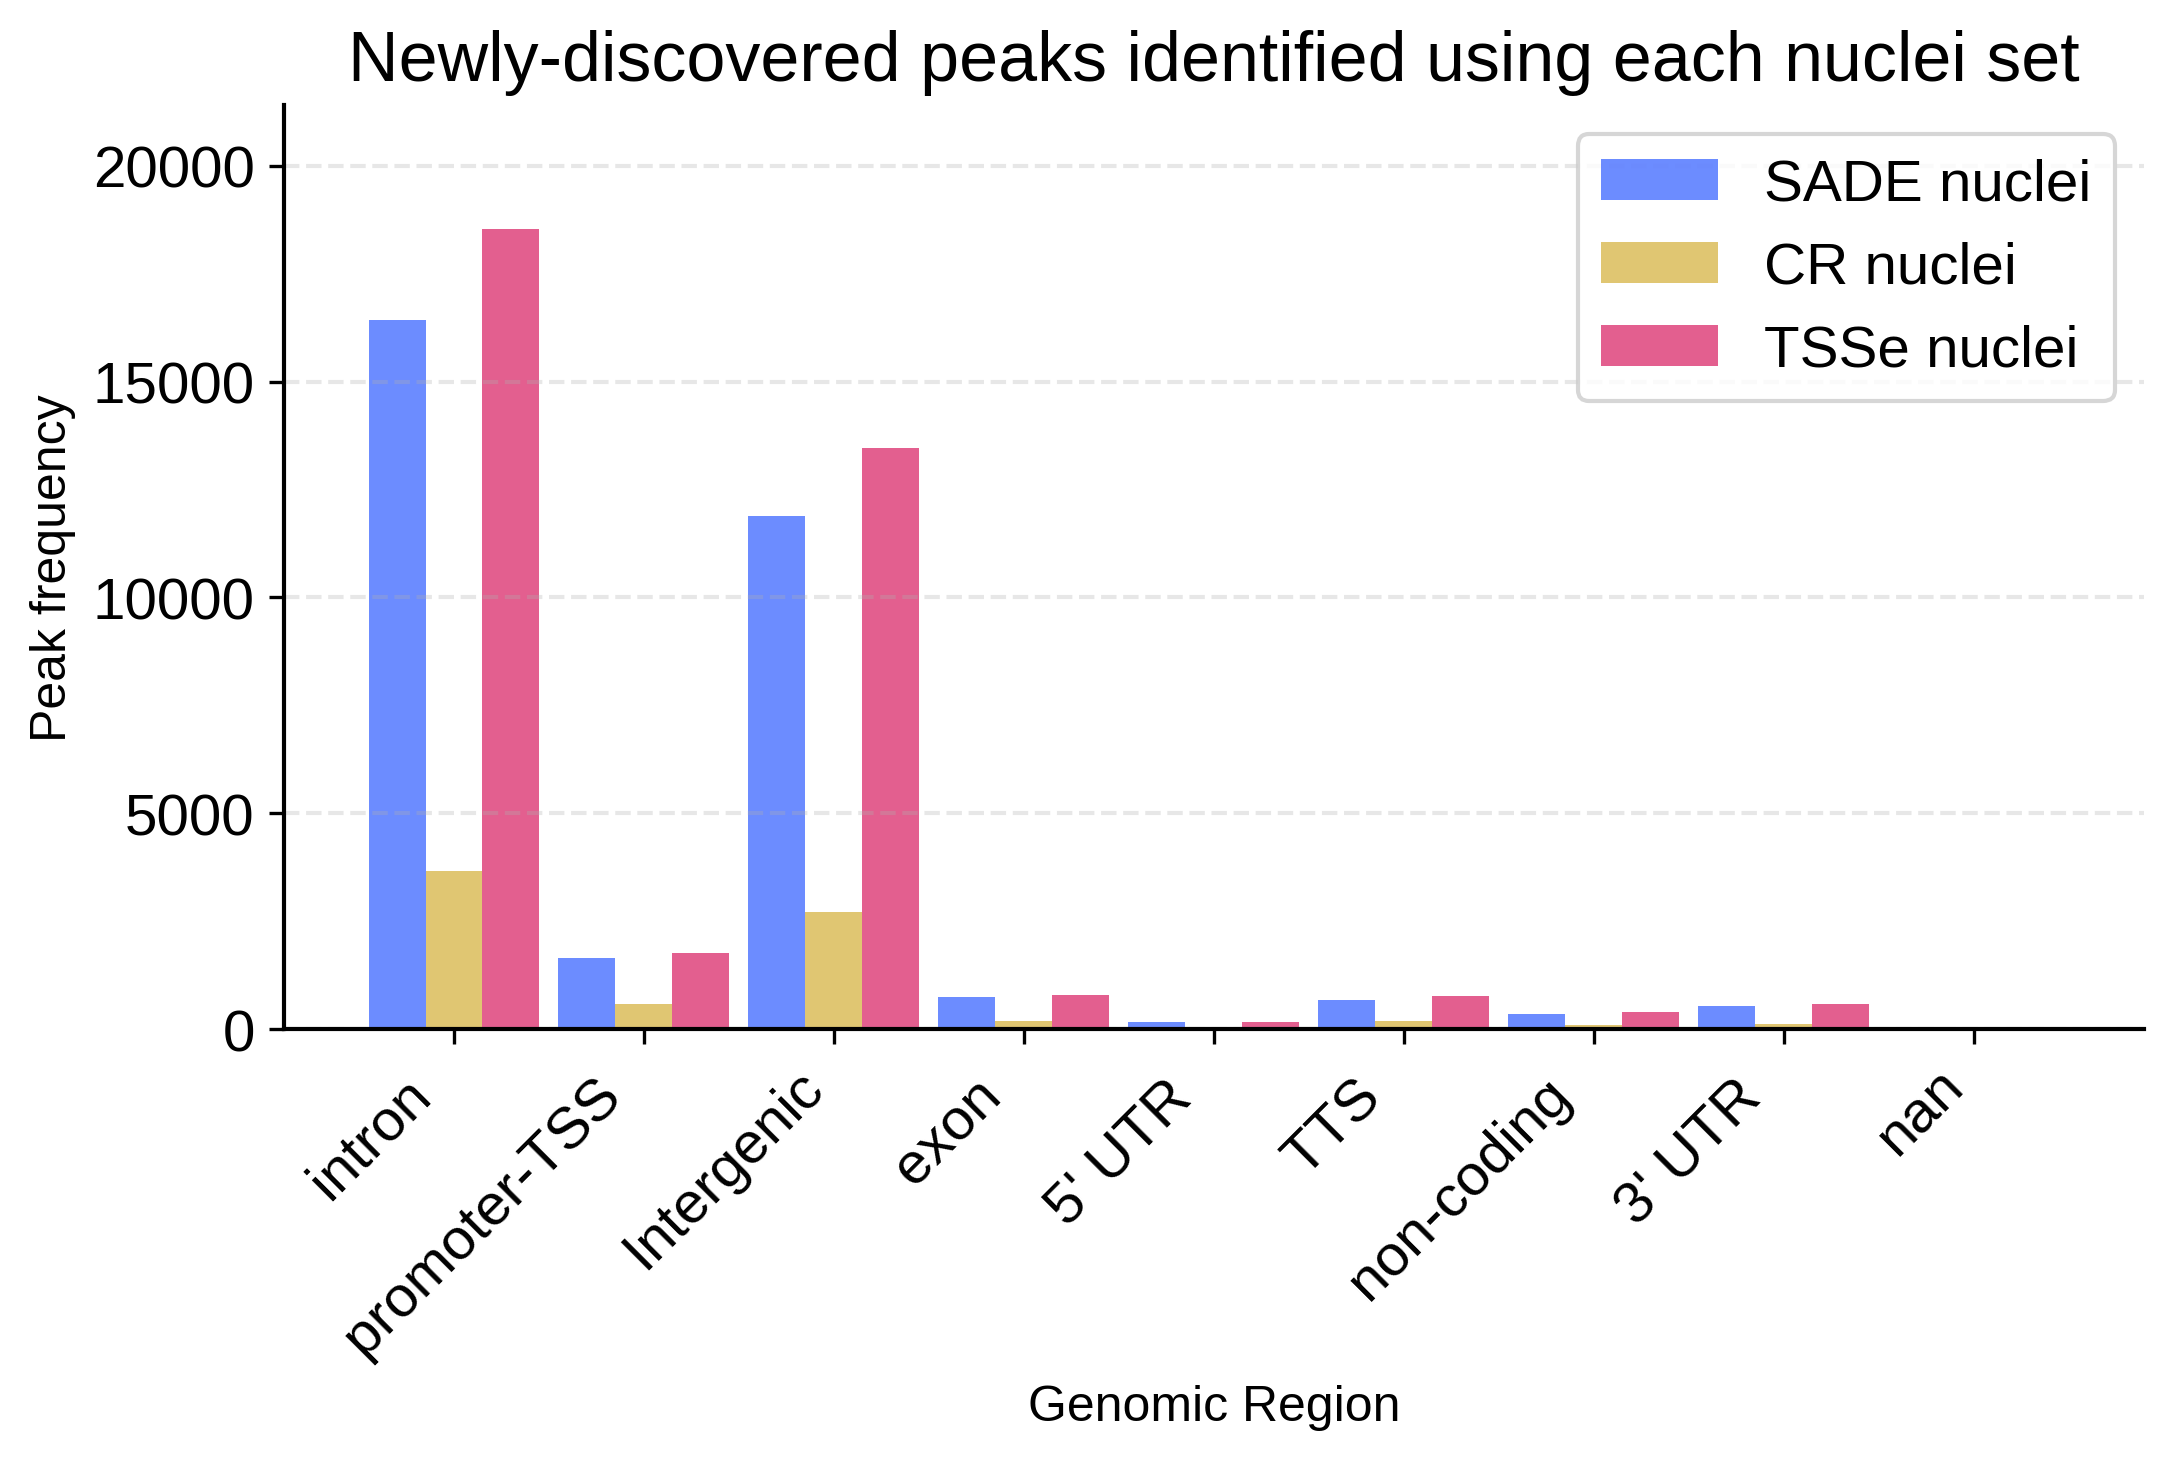

In [12]:
color_map = {'intron ': 'blue', 'promoter-TSS ': 'orange', 'Intergenic': 'skyblue', 'exon ': 'red',
                "5' UTR ": 'purple', 'TTS ': 'brown', 'non-coding ': 'pink', "3' UTR ": 'slateblue', 'nan': 'grey'}
index_map = {'intron ': 0, 'promoter-TSS ': 1, 'Intergenic': 2, 'exon ': 3,
                "5' UTR ": 4, 'TTS ': 5, 'non-coding ': 6, "3' UTR ": 7, 'nan': 8}

width = 0.3  # the width of the bars
fig, ax = plt.subplots( nrows=1, ncols=1, figsize=(8,4))

for d, c, poffset, l in zip([SADE_vs_raw, CR_vs_raw, TSSe_vs_raw], ['#2E5BFF', "#D4AF37", '#D81B60'],
                    0.3*np.array([-1, 0, 1]),
                    ['SADE nuclei', 'CR nuclei', 'TSSe nuclei']):
    freq_df = simplify_annotation(d['newly_discovered_peaks'], inplace=False).value_counts()
    x_positions = [index_map[idx] + poffset for idx in freq_df.index]
    ax.bar(x_positions, freq_df.values, width=0.3, alpha=0.7, color=c, label=f'{l}')


ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.yaxis.grid(True, linestyle='--', alpha=0.3, zorder=0)

ax.set_ylim( 0, ax.get_ylim()[1]*1.1)
ax.set_ylabel('Peak frequency', fontsize=12)
ax.set_xlabel('Genomic Region', fontsize=12) 
ax.legend(loc='upper right', ncols=1, bbox_to_anchor=(1, 1))
ax.set_title('Newly-discovered peaks identified using each nuclei set')


ticks = sorted(index_map.values())
labels = sorted(index_map, key=index_map.get)
ax.set_xticks(ticks)
ax.set_xticklabels(labels, rotation=45, ha='right')


# plt.show()